In [1]:
import pandas as pd
prediction = pd.read_csv('used_cars.csv')
prediction.head()

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
0,Ford,Utility Police Interceptor Base,2013,"51,000 mi.",E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,"$10,300"
1,Hyundai,Palisade SEL,2021,"34,742 mi.",Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,"$38,005"
2,Lexus,RX 350 RX 350,2022,"22,372 mi.",Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,NaN,"$54,598"
3,INFINITI,Q50 Hybrid Sport,2015,"88,900 mi.",Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...,7-Speed A/T,Black,Black,None reported,Yes,"$15,500"
4,Audi,Q3 45 S line Premium Plus,2021,"9,835 mi.",Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,NaN,"$34,999"


In [2]:
train = pd.read_csv('used_cars.csv')
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 4009 entries, 0 to 4008
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   brand         4009 non-null   str  
 1   model         4009 non-null   str  
 2   model_year    4009 non-null   int64
 3   milage        4009 non-null   str  
 4   fuel_type     3839 non-null   str  
 5   engine        4009 non-null   str  
 6   transmission  4009 non-null   str  
 7   ext_col       4009 non-null   str  
 8   int_col       4009 non-null   str  
 9   accident      3896 non-null   str  
 10  clean_title   3413 non-null   str  
 11  price         4009 non-null   str  
dtypes: int64(1), str(11)
memory usage: 376.0 KB


In [3]:
train = pd.read_csv('used_cars.csv')
train.info()
train.describe(include='all')

<class 'pandas.DataFrame'>
RangeIndex: 4009 entries, 0 to 4008
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   brand         4009 non-null   str  
 1   model         4009 non-null   str  
 2   model_year    4009 non-null   int64
 3   milage        4009 non-null   str  
 4   fuel_type     3839 non-null   str  
 5   engine        4009 non-null   str  
 6   transmission  4009 non-null   str  
 7   ext_col       4009 non-null   str  
 8   int_col       4009 non-null   str  
 9   accident      3896 non-null   str  
 10  clean_title   3413 non-null   str  
 11  price         4009 non-null   str  
dtypes: int64(1), str(11)
memory usage: 376.0 KB


,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
count,4009,4009,4009.000000,4009,3839,4009,4009,4009,4009,3896,3413,4009
unique,57,1898,NaN,2818,7,1146,62,319,156,2,1,1569
top,Ford,M3 Base,NaN,"110,000 mi.",Gasoline,2.0L I4 16V GDI DOHC Turbo,A/T,Black,Black,None reported,Yes,"$15,000"
freq,386,30,NaN,16,3309,52,1037,905,2025,2910,3413,39
mean,NaN,NaN,2015.515590,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,NaN,NaN,6.104816,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,NaN,NaN,1974.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,NaN,NaN,2012.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,NaN,NaN,2017.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,NaN,NaN,2020.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
train = pd.read_csv('used_cars.csv')
missing_values = train.isnull().sum()
print(missing_values[missing_values > 0])


fuel_type      170
accident       113
clean_title    596
dtype: int64


In [7]:
train = pd.read_csv('used_cars.csv')
missing_values = train.isnull().sum()
missing_values = missing_values[missing_values > 0]
print(missing_values)

total_data = len(train)
batas = total_data * 0.75 # 75% dari data
less = missing_values[missing_values < batas].index
over = missing_values[missing_values >= batas].index

print(f"\nTotal data landrover: {total_data}")
print(f"Batas 75%: {batas}")
print(f"\nKolom yang bolongnya dikit (<75%) -> bakal kita isi:")
print(list(less))
print(f"\nKolom yang bolongnya banyak (>=75%) -> bakal kita buang:")
print(list(over))

train_clean = train.drop(columns=over)
print(f"\nBentuk data setelah buang kolom parah: {train_clean.shape}")


fuel_type      170
accident       113
clean_title    596
dtype: int64

Total data landrover: 4009
Batas 75%: 3006.75

Kolom yang bolongnya dikit (<75%) -> bakal kita isi:
['fuel_type', 'accident', 'clean_title']

Kolom yang bolongnya banyak (>=75%) -> bakal kita buang:
[]

Bentuk data setelah buang kolom parah: (4009, 12)


In [10]:
numeric_features = train[less].select_dtypes(include=['number']).columns
train[numeric_features] = train[numeric_features].fillna(train[numeric_features].median())


In [28]:
kategorical_features = train[less].select_dtypes(include=['object']).columns
for column in kategorical_features:
    train[column] = train[column].fillna(train[column].mode()[0])
df = train.drop(columns=over)

C:\Users\ASUS\AppData\Local\Temp\ipykernel_16096\3011474564.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  kategorical_features = train[less].select_dtypes(include=['object']).columns


In [29]:
df = train.drop(columns=over)
missing_values = df.isnull().sum()
missing_values[missing_values > 0]

Series([], dtype: int64)

--- Tipe Data Awal ---
brand             str
model             str
model_year      int64
milage            str
fuel_type         str
engine            str
transmission      str
ext_col           str
int_col           str
accident          str
clean_title       str
price           int64
dtype: object

--- Kolom Numerik Terdeteksi ---
['model_year', 'price']


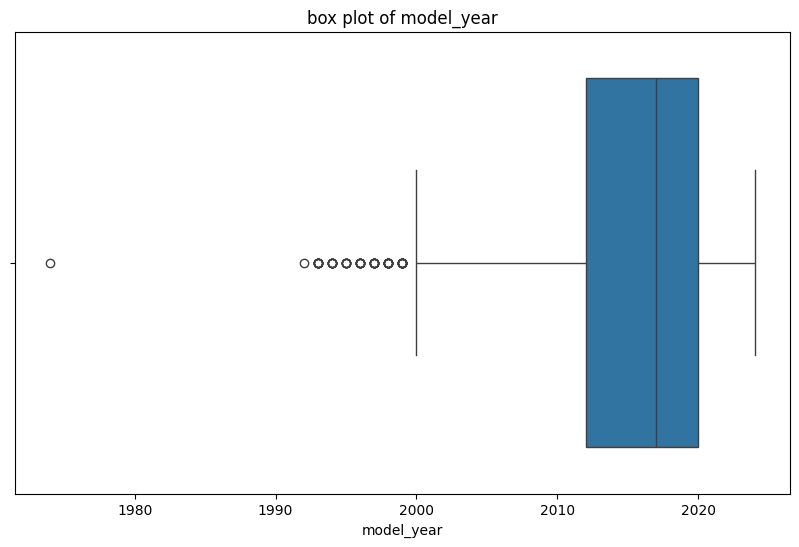

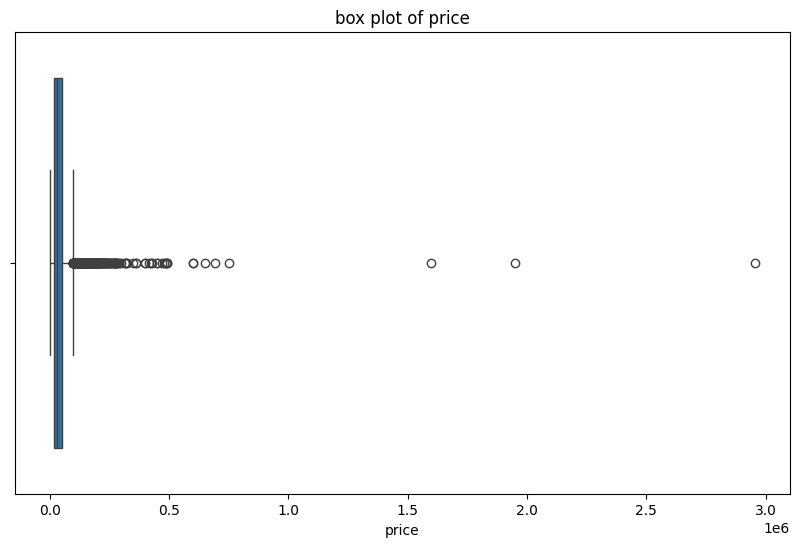

In [42]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Cek nama kolom dan tipe data awal
print("--- Tipe Data Awal ---")
print(df.dtypes)

# 2. Membersihkan & mengonversi kolom angka secara otomatis
for col in df.columns:
    if df[col].dtype == 'object':
        # Hapus karakter non-angka (kecuali titik untuk desimal)
        cleaned = df[col].astype(str).str.replace(r'[^0-9.]', '', regex=True)
        converted = pd.to_numeric(cleaned, errors='coerce')
        
        # Jika sebagian besar isinya berhasil berubah jadi angka, perbarui kolomnya
        if converted.notna().sum() > (len(df) * 0.5):
            df[col] = converted

# 3. Ambil ulang semua kolom numerik
numeric_features = df.select_dtypes(include=['number']).columns.tolist()
print("\n--- Kolom Numerik Terdeteksi ---")
print(numeric_features)

# 4. Plot ulang boxplot
for feature in numeric_features:
    plt.figure(figsize=(10, 6))
    sns.boxplot(x=df[feature])
    plt.title(f'box plot of {feature}')
    plt.show()

In [45]:
import pandas as pd

# 1. Mengidentifikasi outliers menggunakan metode IQR
Q1 = df[numeric_features].quantile(0.25)
Q3 = df[numeric_features].quantile(0.75)
IQR = Q3 - Q1

In [46]:
# 2. Membuat kondisi filter (menentukan baris mana saja yang TIDAK mengandung outlier)
condition = ~((df[numeric_features] < (Q1 - 1.5 * IQR)) | (df[numeric_features] > (Q3 + 1.5 * IQR))).any(axis=1)

# 3. Filter data numerik
df_filtered_numeric = df.loc[condition, numeric_features]

# 4. Ambil kolom kategorikal (seperti model, transmission, fuelType)
# Ganti baris ini:
categorical_features = df.select_dtypes(include=['object', 'string']).columns

# 5. Menggabungkan kembali kolom numerik yang bersih dengan kolom kategorikal
df = pd.concat([df_filtered_numeric, df.loc[condition, categorical_features]], axis=1)

# Cek jumlah data setelah outlier dihapus
print("Jumlah data sebelum:", len(condition))
print("Jumlah data setelah menghapus outlier:", len(df))

Jumlah data sebelum: 3627
Jumlah data setelah menghapus outlier: 3615


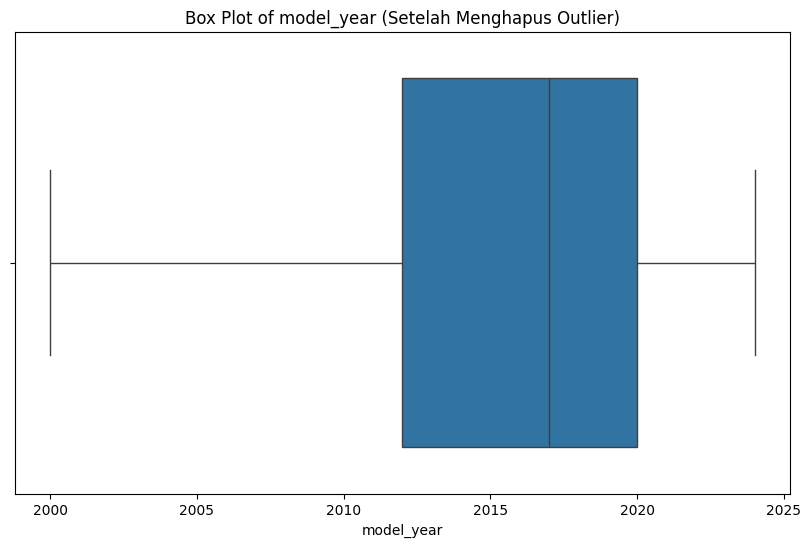

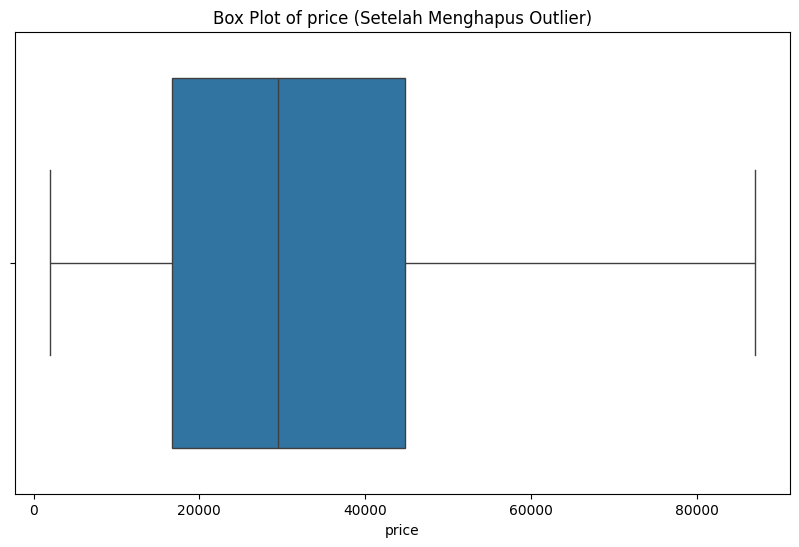

In [47]:
import matplotlib.pyplot as plt
import seaborn as sns

# Menampilkan boxplot setelah outlier dibersihkan
for feature in numeric_features:
    plt.figure(figsize=(10, 6))
    sns.boxplot(x=df[feature])
    plt.title(f'Box Plot of {feature} (Setelah Menghapus Outlier)')
    plt.show()

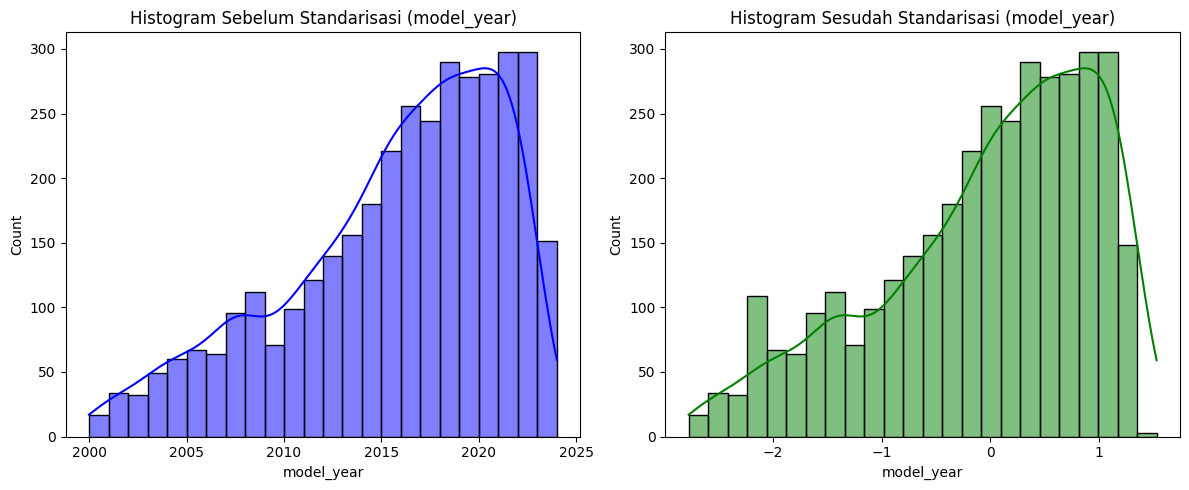

In [48]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

# 1. Tentukan fitur numerik yang di-scale (selain target 'price')
cols_to_scale = [col for col in numeric_features if col != 'price']

# Simpan data asli sebelum standarisasi untuk visualisasi
df_before = df.copy()

# 2. Proses Standarisasi (StandardScaler)
scaler = StandardScaler()
df[cols_to_scale] = scaler.fit_transform(df[cols_to_scale])

# 3. Visualisasi Histogram Perbandingan (Sebelum vs Sesudah Standarisasi)
for feature in cols_to_scale:
    plt.figure(figsize=(12, 5))
    
    # Subplot 1: Sebelum Standarisasi
    plt.subplot(1, 2, 1)
    sns.histplot(df_before[feature], kde=True, color='blue')
    plt.title(f'Histogram Sebelum Standarisasi ({feature})')
    
    # Subplot 2: Sesudah Standarisasi
    plt.subplot(1, 2, 2)
    sns.histplot(df[feature], kde=True, color='green')
    plt.title(f'Histogram Sesudah Standarisasi ({feature})')
    
    plt.tight_layout()
    plt.show()

In [49]:
# 1. Cek jumlah data duplikat
duplicates = df.duplicated()
print("Jumlah baris duplikat:", duplicates.sum())
print("\nDetail baris duplikat:")
print(df[duplicates])

# 2. Hapus data duplikat (jika ada)
df = df.drop_duplicates()

print("\nJumlah data setelah menghapus duplikat:", len(df))

Jumlah baris duplikat: 0

Detail baris duplikat:
Empty DataFrame
Columns: [model_year, price, brand, model, milage, fuel_type, engine, transmission, ext_col, int_col, accident, clean_title]
Index: []

Jumlah data setelah menghapus duplikat: 3615


In [51]:
import pandas as pd

# 1. Filter dataset agar HANYA berisi mobil Land Rover / Range Rover
# (Sesuaikan 'brand' dengan nama kolom merek di dataset kamu, misal 'brand' atau 'manufacturer')
df_landrover = df[df['brand'].str.contains('Land Rover|Range Rover', case=False, na=False)].copy()

# Hapus kolom 'brand' / 'manufacturer' karena semuanya sudah pasti Land Rover
if 'brand' in df_landrover.columns:
    df_landrover = df_landrover.drop(columns=['brand'])

print("Jumlah data Land Rover:", len(df_landrover))

# 2. Ambil fitur kategorikal khusus Land Rover
categorical_features = df_landrover.select_dtypes(include=['object', 'string']).columns.tolist()

# 3. Lakukan One-Hot Encoding (Ubah True/False jadi angka 1 dan 0 dengan dtype=int)
df_encoded = pd.get_dummies(df_landrover, columns=categorical_features, drop_first=True, dtype=int)

# 4. Cek ukuran dataset yang baru
print("Ukuran dataset setelah encoding yang benar:", df_encoded.shape)
df_encoded.head()

Jumlah data Land Rover: 0
Ukuran dataset setelah encoding yang benar: (0, 2)


,model_year,price


In [50]:
# 1. Ambil nama kolom kategorikal/teks
categorical_features = df.select_dtypes(include=['object', 'string']).columns.tolist()

# 2. Terapkan One-Hot Encoding
df_encoded = pd.get_dummies(df, columns=categorical_features, drop_first=True)

# 3. Cek hasil dataset yang sudah berubah jadi angka semua
print("Ukuran dataset setelah encoding:", df_encoded.shape)
df_encoded.head()

Ukuran dataset setelah encoding: (3615, 5804)


,model_year,price,brand_Alfa,brand_Aston,brand_Audi,brand_BMW,brand_Bentley,brand_Buick,brand_Cadillac,brand_Chevrolet,...,int_col_Titan Black / Quarzit,int_col_Tupelo,int_col_Very Light Cashmere,int_col_Walnut,int_col_Whisper Beige,int_col_White,int_col_White / Brown,int_col_Yellow,int_col_–,accident_None reported
0,-0.443476,10300,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,0.991767,38005,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,1.171172,54598,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,True
3,-0.084665,15500,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,True
4,0.991767,34999,False,False,True,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,True


In [52]:
# Cek semua nama merek unik yang ada di dataset
print(df['brand'].unique())

<StringArray>
[         'Ford',       'Hyundai',         'Lexus',      'INFINITI',
          'Audi',         'Acura',           'BMW',         'Tesla',
          'Land',        'Toyota',       'Lincoln',        'Jaguar',
         'Dodge',        'Nissan',       'Genesis',     'Chevrolet',
 'Mercedes-Benz',           'Kia',          'Jeep',       'Bentley',
         'Honda',          'MINI',       'Porsche',        'Hummer',
      'Chrysler',         'Volvo',      'Cadillac',      'Maserati',
    'Volkswagen',        'Subaru',           'GMC',           'RAM',
         'Lucid',          'Alfa',         'Scion',    'Mitsubishi',
         'Mazda',        'Saturn',      'Polestar',         'Buick',
         'Aston',         'Lotus',   'Rolls-Royce',          'FIAT',
         'Karma',          'Saab',       'Mercury',       'Pontiac',
      'Plymouth',        'Rivian',         'smart',       'Maybach',
        'Suzuki']
Length: 53, dtype: str


In [53]:
import pandas as pd

# 1. Filter khusus merek 'Land' (atau yang mengandung kata 'Land')
df_landrover = df[df['brand'].str.contains('Land', case=False, na=False)].copy()

print("Jumlah data Land Rover terdeteksi:", len(df_landrover))

# 2. Hapus kolom 'brand' agar tidak dibuatkan ribuan dummy variabel untuk merek lain
if 'brand' in df_landrover.columns:
    df_landrover = df_landrover.drop(columns=['brand'])

# 3. Ambil kolom kategorikal yang tersisa (seperti model, transmission, fuelType)
categorical_features = df_landrover.select_dtypes(include=['object', 'string']).columns.tolist()

# 4. Terapkan One-Hot Encoding (menggunakan dtype=int agar outputnya angka 1 dan 0, bukan True/False)
df_encoded = pd.get_dummies(df_landrover, columns=categorical_features, drop_first=True, dtype=int)

print("Ukuran dataset setelah encoding yang benar:", df_encoded.shape)
df_encoded.head()

Jumlah data Land Rover terdeteksi: 108
Ukuran dataset setelah encoding yang benar: (108, 238)


,model_year,price,model_Rover Defender S,model_Rover Defender SE,model_Rover Defender X-Dynamic SE,model_Rover Discovery HSE,model_Rover Discovery HSE LUXURY,model_Rover Discovery S,model_Rover Discovery SE,model_Rover Discovery Sport HSE,...,int_col_Espresso,int_col_Gray,int_col_Ivory / Ebony,int_col_Pimento / Ebony,int_col_Red,int_col_Tan/Ebony,int_col_Tan/Ebony/Ebony,int_col_White,int_col_–,accident_None reported
10,0.991767,73897,0,0,0,0,0,0,0,0,...,0,0,0,1,0,0,0,0,0,1
15,-0.443476,29990,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
80,0.812361,37998,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
110,0.094740,18000,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
120,0.453551,30775,0,0,0,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0


In [54]:
import pandas as pd

# Menghitung jumlah dan persentase missing values di setiap kolom
missing_values = df_encoded.isnull().sum()
missing_percentage = (missing_values / len(df_encoded)) * 100

# Membuat DataFrame ringkasan missing values
missing_data = pd.DataFrame({
    'Missing Values': missing_values,
    'Percentage': missing_percentage
}).sort_values(by='Missing Values', ascending=False)

# Tampilkan 10 kolom teratas untuk memastikan tidak ada data yang kosong (harus 0)
missing_data.head(10)

,Missing Values,Percentage
model_year,0,0.0
price,0,0.0
model_Rover Defender S,0,0.0
model_Rover Defender SE,0,0.0
model_Rover Defender X-Dynamic SE,0,0.0
model_Rover Discovery HSE,0,0.0
model_Rover Discovery HSE LUXURY,0,0.0
model_Rover Discovery S,0,0.0
model_Rover Discovery SE,0,0.0
model_Rover Discovery Sport HSE,0,0.0


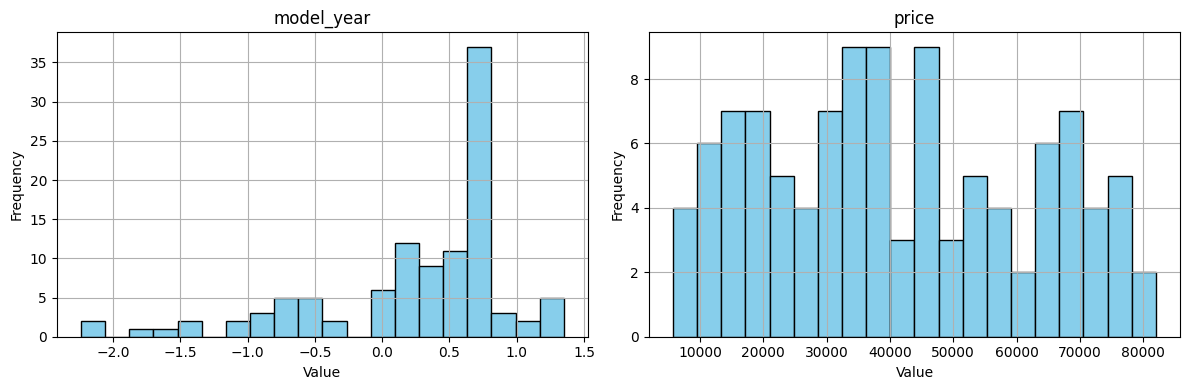

In [56]:
import matplotlib.pyplot as plt

# Ambil kolom numerik utama saja agar tidak membludak
main_cols = ['model_year', 'price']

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for i, col in enumerate(main_cols):
    df_encoded[col].hist(ax=axes[i], bins=20, color='skyblue', edgecolor='black')
    axes[i].set_title(col)
    axes[i].set_xlabel('Value')
    axes[i].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

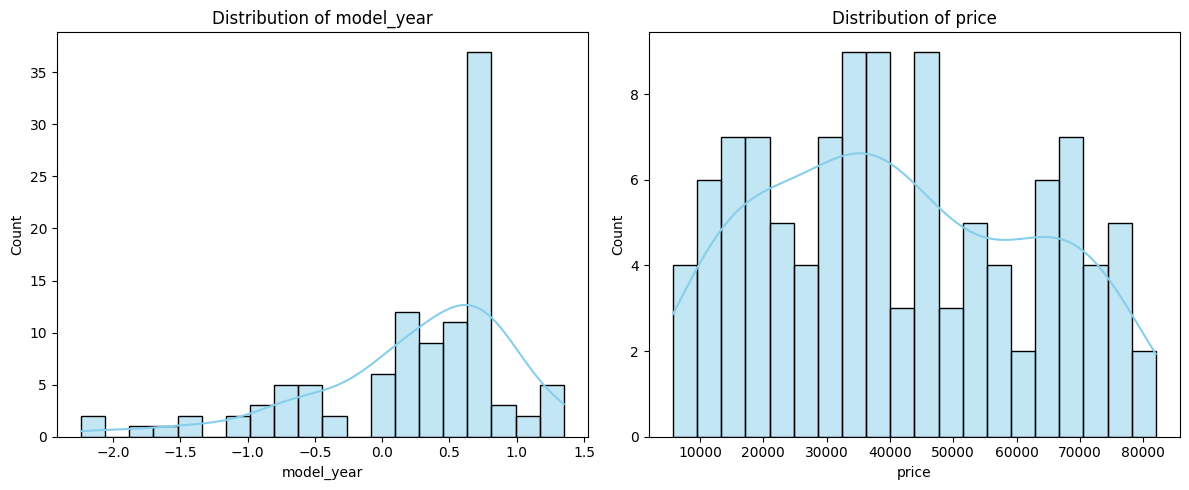

In [57]:
import matplotlib.pyplot as plt
import seaborn as sns

# Visualisasi distribusi data untuk beberapa kolom utama
columns_to_plot = ['model_year', 'price']

plt.figure(figsize=(12, 5))
for i, column in enumerate(columns_to_plot, 1):
    plt.subplot(1, 2, i)
    sns.histplot(df_encoded[column], kde=True, bins=20, color='skyblue')
    plt.title(f'Distribution of {column}')

plt.tight_layout()
plt.show()

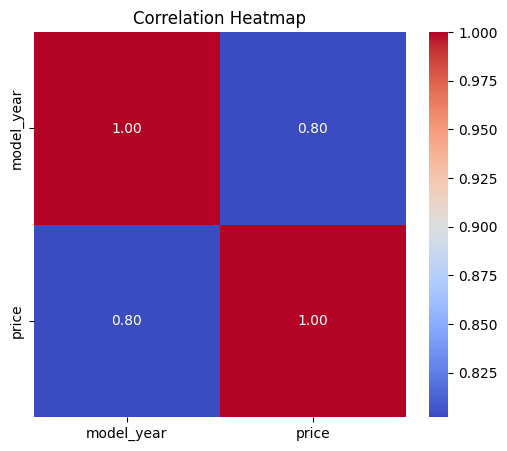

In [58]:
# Visualisasi Matriks Korelasi (Heatmap) antara model_year dan price
plt.figure(figsize=(6, 5))
sns.heatmap(df_encoded[['model_year', 'price']].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

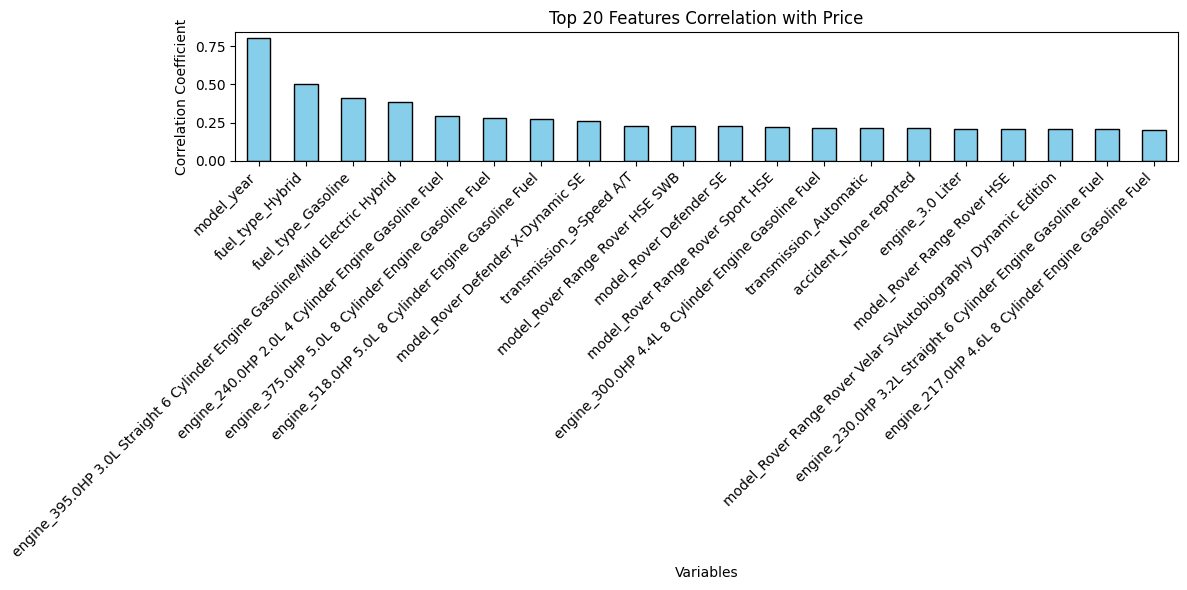

In [59]:
import matplotlib.pyplot as plt

# 1. Menghitung korelasi antara target 'price' dan fitur lainnya
target_corr = df_encoded.corr()['price']

# 2. Mengurutkan berdasarkan korelasi absolut (tertinggi ke terendah)
target_corr_sorted = target_corr.abs().sort_values(ascending=False)

# 3. Mengambil Top 20 fitur paling berkorelasi (mengabaikan 'price' itu sendiri)
top_corr = target_corr_sorted[1:21]

# 4. Visualisasi Bar Plot Korelasi
plt.figure(figsize=(12, 6))
top_corr.plot(kind='bar', color='skyblue', edgecolor='black')
plt.title('Top 20 Features Correlation with Price')
plt.xlabel('Variables')
plt.ylabel('Correlation Coefficient')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [60]:
from sklearn.model_selection import train_test_split

# 1. Memisahkan fitur (X) dan target (y)
X = df_encoded.drop(columns=['price'])
y = df_encoded['price']

# 2. Membagi dataset menjadi training dan testing set
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Menghitung panjang/jumlah data (sesuai contoh di modul)
print("Jumlah data: ", len(X))
print("Jumlah data latih: ", len(X_train))
print("Jumlah data test: ", len(X_test))

Jumlah data:  108
Jumlah data latih:  86
Jumlah data test:  22


In [61]:
from sklearn import tree
from sklearn.model_selection import cross_val_score

# 1. Membuat model dengan Decision Tree Regressor (karena memprediksi harga)
clf = tree.DecisionTreeRegressor(random_state=42)

# 2. Mengevaluasi performa model dengan cross_val_score (5 folds)
scores = cross_val_score(clf, X, y, cv=5)

# Menampilkan hasil skor R2 tiap fold dan rata-ratanya
print("Skor untuk setiap fold:", scores)
print("Rata-rata skor cross validation:", scores.mean())

Skor untuk setiap fold: [-0.32596578  0.07268235  0.65007765  0.54643578  0.70114469]
Rata-rata skor cross validation: 0.3288749370317084
